# Reddit (Arctic Shift) loader — economics & finance subreddits

Pulls posts (and optionally comments) for a chosen set of subreddits out of the
[`open-index/arctic`](https://huggingface.co/datasets/open-index/arctic) Hugging Face
dataset and saves them as small local Parquet files you can load in any notebook.

**How it works.** The dataset is ~1.3 TB of Parquet split **by month only** (`data/{kind}/YYYY/MM/NNN.parquet`,
~200 MB shards), not by subreddit. So the loader downloads each shard once, keeps only the rows for your
subreddits, writes those to `data/raw/…`, and deletes the shard. Your disk only ever holds a few shards plus
the filtered output.

**Things to know before running the full pull**
- **Coverage:** submissions run from 2005‑12 to 2026‑02, but comments stop at **2022‑07**.
- **Cost:** you download the full size of every month in your range, whatever subreddits you pick. Section 3
  prints the total for your settings before anything big runs. Submissions for 2010–2026 come to about 300 GB.
  Comments are roughly 3× bigger per month.
- **Resumable:** each finished shard is recorded on disk, so if you interrupt the run (or your laptop sleeps),
  re-run the cell and it picks up where it stopped.
- **Reproducible:** the dataset is still being updated, so the notebook pins the exact dataset version
  (commit hash) and saves it with your data.
- **Caveat for research:** `score` / `num_comments` were captured when Arctic Shift archived the item
  (often shortly after posting), so treat them as early snapshots, not final values.

## 0. Setup

In [58]:
%pip install -q -U duckdb huggingface_hub
%pip install -q pyarrow tqdm matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [59]:
import json, os, re, shutil, tempfile, time, traceback
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import duckdb
import pandas as pd
from huggingface_hub import HfApi, hf_hub_download, get_token
from tqdm.auto import tqdm

print("duckdb", duckdb.__version__)

duckdb 1.5.6


## 1. Configuration

Edit this cell. Subreddit names are case-insensitive. If you later change the subreddit list, also change `RUN_NAME`
(or delete that folder): the filtered files only contain the subreddits that were requested when they were made.

In [89]:
REPO = "open-index/arctic"

SUBREDDITS = [
    "Economics", "economy", "AskEconomics"       # macro / economic discussion
]

START = "2010-01"          # inclusive, YYYY-MM
END   = "2026-02"          # inclusive, YYYY-MM

KINDS = ["submissions"]    # add "comments" for comments (available only up to 2022-07, ~3x the download)

RUN_NAME = "econ_sentiment"
DATA_DIR = Path("data") / RUN_NAME   # relative to this notebook
WORKERS  = 4                         # parallel shard downloads; lower to 2 on slow Wi-Fi
SAMPLE_FRAC = 0.1

# Columns kept in the filtered output (any that don't exist in a shard are skipped)
COLUMNS = {
    "submissions": ["id", "subreddit", "author", "created_utc", "created_at", "title", "selftext",
                    "score", "num_comments", "url", "link_flair_text", "over_18"],
    "comments":    ["id", "subreddit", "author", "created_utc", "created_at", "body",
                    "score", "link_id", "parent_id"],
}

## 2. Connect to Hugging Face and pin the dataset version

A free Hugging Face token gives you much higher rate limits, which matters for a multi-hour download. Create one
at https://huggingface.co/settings/tokens (choose "Read" access) and run `hf auth login` once in a terminal (older versions: `huggingface-cli login`), or set
the `HF_TOKEN` environment variable. The loader also works without a token, just slower.

In [90]:
api = HfApi()
TOKEN = get_token()
print("HF token found ✓" if TOKEN else "⚠️  No HF token: downloads will be rate-limited (see note above).")

META = DATA_DIR / "_meta"
META.mkdir(parents=True, exist_ok=True)

# Pin the dataset commit. Reuse the one saved for this RUN_NAME so a resumed run stays consistent.
rev_file = META / "revision.json"
if rev_file.exists():
    REV = json.loads(rev_file.read_text())["revision"]
    print("Using pinned revision from earlier run:", REV)
else:
    REV = api.dataset_info(REPO, token=TOKEN).sha
    rev_file.write_text(json.dumps({"repo": REPO, "revision": REV,
                                    "pinned_at": pd.Timestamp.utcnow().isoformat()}, indent=2))
    print("Pinned new revision:", REV)

# Record (and guard) the subreddit set for this run
_subs_norm = sorted({s.strip().lower() for s in SUBREDDITS})
assert all(re.fullmatch(r"[a-z0-9_]+", s) for s in _subs_norm), "Subreddit names should be letters/digits/_ only"
subs_file = META / "subreddits.json"
if subs_file.exists() and json.loads(subs_file.read_text()) != _subs_norm:
    raise ValueError(f"{DATA_DIR} was built for a different subreddit list. "
                     "Change RUN_NAME (or delete that folder) to start a new run.")
subs_file.write_text(json.dumps(_subs_norm, indent=2))

HF token found ✓
Pinned new revision: da567f9441c5a7ebf02d13eeeaa020b11f321f8d


48

## 3. Inventory: which shards exist and how much will be downloaded

In [91]:
def month_range(start, end):
    return [p.strftime("%Y-%m") for p in pd.period_range(start, end, freq="M")]

def list_shards(kind):
    # Return {"YYYY-MM": [repo paths...]} for one kind, cached per revision.
    cache = META / f"files_{kind}_{REV[:10]}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    out = {}
    for f in api.list_repo_tree(REPO, path_in_repo=f"data/{kind}", recursive=True,
                                repo_type="dataset", revision=REV, token=TOKEN):
        m = re.fullmatch(rf"data/{kind}/(\d{{4}})/(\d{{2}})/[^/]+\.parquet", f.path)
        if m:
            out.setdefault(f"{m[1]}-{m[2]}", []).append(f.path)
    out = {k: sorted(v) for k, v in sorted(out.items())}
    cache.write_text(json.dumps(out))
    return out

stats = pd.read_csv(hf_hub_download(REPO, "stats.csv", repo_type="dataset", revision=REV, token=TOKEN))
stats["month"] = stats["year"].astype(str) + "-" + stats["month"].astype(int).map("{:02d}".format)

SHARDS = {k: list_shards(k) for k in KINDS}
months = month_range(START, END)

rows = []
for kind in KINDS:
    avail = [m for m in months if m in SHARDS[kind]]
    missing = [m for m in months if m not in SHARDS[kind]]
    s = stats[(stats["type"] == kind) & stats["month"].isin(avail)]
    rows.append({"kind": kind, "months_available": len(avail), "months_missing": len(missing),
                 "first": avail[0] if avail else None, "last": avail[-1] if avail else None,
                 "shards": sum(len(SHARDS[kind][m]) for m in avail),
                 "download_GB": round(s["size_bytes"].sum() / 1e9, 1)})
    if missing:
        print(f"{kind}: no data for {len(missing)} month(s), e.g. {missing[:3]} … {missing[-3:]}")
plan = pd.DataFrame(rows)
display(plan)
print("Rough time at 20 MB/s:", round(plan.download_GB.sum() * 1e3 / 20 / 3600, 1), "hours "
      "(the filtering itself is fast; your connection speed decides the total time)")

submissions: no data for 16 month(s), e.g. ['2011-06', '2022-09', '2022-10'] … ['2023-09', '2023-10', '2023-11']


,kind,months_available,months_missing,first,last,shards,download_GB
0,submissions,178,16,2010-01,2026-02,5734,350.0


Rough time at 20 MB/s: 4.9 hours (the filtering itself is fast; your connection speed decides the total time)


## 4. The filtering engine

`process_shard` downloads one shard to a temporary folder, uses DuckDB to keep only your subreddits, writes
`data/<RUN_NAME>/raw/<kind>/<YYYY-MM>/<shard>.parquet`, and deletes the download. A shard's output file
exists only once that shard is completely finished (it is written under a temporary name, then renamed), so
re-running skips finished work. Shards that fail are retried with a growing wait between attempts.

In [ ]:
RAW = DATA_DIR / "raw"
TMP = DATA_DIR / "_tmp"

def out_path(kind, repo_path):
    yyyy, mm, fname = repo_path.split("/")[-3:]
    return RAW / kind / f"{yyyy}-{mm}" / fname

def download_shard(repo_path, dest_dir):
    # Separated out so it can be swapped (e.g. for testing).
    return hf_hub_download(REPO, repo_path, repo_type="dataset", revision=REV,
                           token=TOKEN, local_dir=dest_dir)

def filter_parquet(src, dst, kind):
    con = duckdb.connect()
    try:
        con.execute("SET threads = 2")
        src_sql = str(src).replace("'", "''")
        have = {r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet('{src_sql}')").fetchall()}
        cols = ", ".join(f'"{c}"' for c in COLUMNS[kind] if c in have)
        subs = ", ".join(f"'{s}'" for s in _subs_norm)
        tmp_dst = dst.with_suffix(".parquet.partial")
        sample_sql = f"AND hash(id) % 1000 < {int(SAMPLE_FRAC * 1000)}" if SAMPLE_FRAC < 1 else ""
        n = con.execute(f'''
            COPY (SELECT {cols} FROM read_parquet('{src_sql}')
                  WHERE lower(subreddit) IN ({subs}) {sample_sql})
            TO '{str(tmp_dst).replace("'", "''")}' (FORMAT parquet, COMPRESSION zstd)
        ''').fetchone()[0]   # COPY returns the number of rows written
        os.replace(tmp_dst, dst)   # atomic: dst exists only when complete
        return n
    finally:
        con.close()

def process_shard(kind, repo_path, retries=4):
    dst = out_path(kind, repo_path)
    if dst.exists():
        return repo_path, "skipped", None
    dst.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(1, retries + 1):
        work = Path(tempfile.mkdtemp(dir=TMP))
        try:
            local = download_shard(repo_path, work)
            n = filter_parquet(local, dst, kind)
            return repo_path, "done", n
        except Exception as e:
            err = f"{type(e).__name__}: {e}"
            if attempt == retries:
                return repo_path, "failed", err
            time.sleep(min(30 * 2 ** (attempt - 1), 300))   # 30s, 60s, 120s ...
        finally:
            shutil.rmtree(work, ignore_errors=True)

def run(kind, months, workers=WORKERS):
    # Process every shard for `kind` in `months`. Safe to interrupt and re-run.
    TMP.mkdir(parents=True, exist_ok=True)
    todo = [p for m in months for p in SHARDS[kind].get(m, [])]
    remaining = [p for p in todo if not out_path(kind, p).exists()]
    print(f"{kind}: {len(todo)} shards in range, {len(todo) - len(remaining)} already done, {len(remaining)} to go")
    found, failed = 0, []
    with ThreadPoolExecutor(max_workers=workers) as ex:
        futs = [ex.submit(process_shard, kind, p) for p in remaining]
        bar = tqdm(as_completed(futs), total=len(futs), desc=kind, unit="shard")
        for f in bar:
            path, status, info = f.result()
            if status == "done":
                found += info
                bar.set_postfix(rows_kept=f"{found:,}")
            elif status == "failed":
                failed.append((path, info))
    log = META / f"failed_{kind}.json"
    if failed:
        log.write_text(json.dumps(failed, indent=2))
        print(f"⚠️  {len(failed)} shard(s) failed; listed in {log}. Re-run this cell to retry them.")
    else:
        log.unlink(missing_ok=True)
        print(f"✓ {kind}: all shards in range finished ({found:,} new rows kept this session)")
    return failed

## 5. Smoke test on one month

Run this first. It processes a single month of submissions (about 5 GB of download), so you can check that
everything works and see how long one month takes on your connection before starting the full pull.

In [92]:
TEST_MONTH = ["2024-01", "2024-02", "2024-03", "2024-04", "2024-05", "2024-06"]
t0 = time.time()
run("submissions", [TEST_MONTH])
print(f"took {time.time() - t0:.0f}s")

test = duckdb.sql(
    f"SELECT * \
    FROM read_parquet('{RAW}/submissions/{TEST_MONTH}/*.parquet') \
    WHERE selftext IS NOT NULL \
    AND selftext NOT IN ('[removed]', '[deleted]')").df()
display(test["subreddit"].value_counts())
test[["created_at", "subreddit", "title", "selftext"]].head(10)
test = test[['subreddit', 'created_at', 'title', 'selftext']]
test.head()

TypeError: unhashable type: 'list'

In [88]:
finance = test[test['subreddit'] == 'finance']
finance['selftext'] = finance['selftext'].astype(str).str.lower().str.replace(r'[^a-z0-9\s.,;"]', '', regex=True).str.strip()
finance = finance[~((finance['selftext'] == "") & (finance['selftext'] == "removed") & (finance['selftext'] == "deleted"))]
finance[['selftext', 'title']]

/var/folders/z4/4j8f00gx7m1_gxdmyxzz2b080000gn/T/ipykernel_69662/1463591478.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  finance['selftext'] = finance['selftext'].astype(str).str.lower().str.replace(r'[^a-z0-9\s.,;"]', '', regex=True).str.strip()


,selftext,title
340,,A Journey from Divorce to financial independence
363,,Southeast Asian fintech Salmon acquires contro...
406,,you are intellectually lazy
413,,US SEC approves bitcoin ETFs
482,,Как зарабатывать на недвижимости
...,...,...
18265,,Elon Musk Is Overpaid
18327,,Abrdn announces £150m cost-cutting drive with ...
18381,,"Real Estate Investment Cashflow Analyzer Pro, ..."
18452,,Bilt Rewards more than doubles its billion-dol...


## 6. Full pull

Set `GO = True` and run. This is the long step. You can stop it at any time (⏹ / interrupt kernel) and re-run
to resume. Keep the laptop plugged in and stop it from sleeping (on a Mac, run `caffeinate -i` in a Terminal
window while the pull runs).

In [70]:
GO = False

if GO:
    for kind in KINDS:
        run(kind, months)
else:
    print("Set GO = True to start the full download.")

Set GO = True to start the full download.


## 7. Load the data

This works in any later notebook once the files exist. Copy the `load_reddit` function, or `%run` this notebook
with `GO = False`. Loading goes through DuckDB, so you can filter by date or subreddit before anything reaches
pandas, which matters for large sets like r/wallstreetbets comments.

In [71]:
def load_reddit(kind="submissions", subreddits=None, start=None, end=None, columns=None,
                data_dir=DATA_DIR, drop_removed=False):
    # Load filtered Reddit data into a DataFrame.
    #   kind:        "submissions" or "comments"
    #   subreddits:  list of names (case-insensitive) or None for all in the run
    #   start / end: "YYYY-MM-DD" bounds on created_at (end is exclusive)
    #   columns:     subset of columns, or None for all
    #   drop_removed: drop rows whose text was deleted/removed
    # Adds `text` (title + selftext for posts, body for comments) and `is_removed`.
    glob = str(Path(data_dir) / "raw" / kind / "*" / "*.parquet")
    where = ["1=1"]
    if subreddits:
        where.append("lower(subreddit) IN (" + ", ".join(f"'{s.lower()}'" for s in subreddits) + ")")
    if start:
        where.append(f"created_at >= TIMESTAMP '{start}'")
    if end:
        where.append(f"created_at < TIMESTAMP '{end}'")
    if kind == "submissions":
        text = "trim(coalesce(title,'') || ' ' || CASE WHEN selftext IN ('[deleted]','[removed]') THEN '' ELSE coalesce(selftext,'') END)"
        removed = "(selftext IN ('[deleted]','[removed]') OR title IN ('[deleted]','[removed]','[deleted by user]'))"
    else:
        text = "CASE WHEN body IN ('[deleted]','[removed]') THEN '' ELSE coalesce(body,'') END"
        removed = "(body IN ('[deleted]','[removed]'))"
    sel = "*" if columns is None else ", ".join(f'"{c}"' for c in columns)
    q = f'''
        SELECT {sel}, {text} AS text, {removed} AS is_removed
        FROM read_parquet('{glob}', union_by_name = true)
        WHERE {" AND ".join(where)}
        {"AND NOT " + removed if drop_removed else ""}
        ORDER BY created_at
    '''
    return duckdb.sql(q).df()

posts = load_reddit("submissions")
print(f"{len(posts):,} posts, {posts.created_at.min()} → {posts.created_at.max()}")
posts.head()

28,283 posts, 2024-01-01 00:20:02 → 2024-01-31 23:59:27


,id,subreddit,author,created_utc,created_at,title,selftext,score,num_comments,url,link_flair_text,over_18,text,is_removed
0,18vktyf,Economics,LoansPayDayOnline,1704068402,2024-01-01 00:20:02,Where did Americans put their money this year?...,,1,1,https://www.livemint.com/money/where-did-ameri...,News,False,Where did Americans put their money this year?...,False
1,18vmopr,Economics,Sea-Barber9329,1704074692,2024-01-01 02:04:52,Predictions for 2024,So much friction happening globally and so man...,1,1,https://amp.theguardian.com/world/2023/dec/31/...,None,False,Predictions for 2024 So much friction happenin...,False
2,18vpory,Economics,Fit-Code-5141,1704086183,2024-01-01 05:16:23,"""India's 2024 Economic Outlook: Fastest-Growin...",,1,1,https://www.consciounessofworld.com/2024/01/in...,None,False,"""India's 2024 Economic Outlook: Fastest-Growin...",False
3,18vqks3,Economics,donutloop,1704089731,2024-01-01 06:15:31,India’s Russian oil imports hit 11-month low i...,,1,1,https://indianexpress.com/article/business/eco...,None,False,India’s Russian oil imports hit 11-month low i...,False
4,18vrxbk,Economics,BeautifulLife1,1704095310,2024-01-01 07:48:30,US debt will become unsustainable and trigger ...,,1,0,https://markets.businessinsider.com/news/bonds...,None,False,US debt will become unsustainable and trigger ...,False


## 8. Sanity check: posts per month by subreddit

Look for gaps or sudden jumps before building any sentiment measure. Those usually mean missing archive data,
a subreddit being created or shut down, or a moderation change, not a change in sentiment.

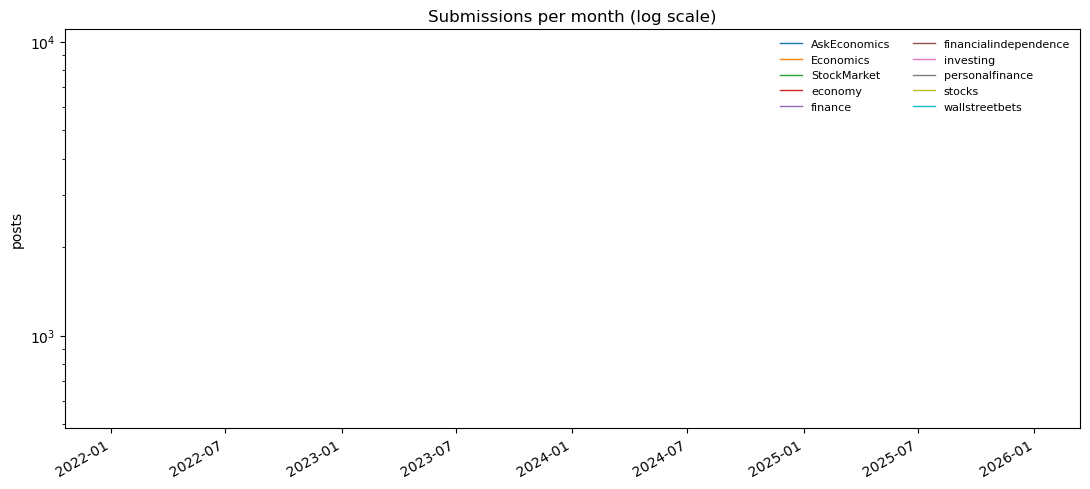

subreddit,AskEconomics,Economics,StockMarket,economy,finance,financialindependence,investing,personalfinance,stocks,wallstreetbets
month,,,,,,,,,,
2024-01-01,625,1132,891,1698,559,803,2490,9545,2262,8278


In [72]:
import matplotlib.pyplot as plt

monthly = duckdb.sql(f'''
    SELECT date_trunc('month', created_at) AS month, subreddit, count(*) AS n
    FROM read_parquet('{RAW}/submissions/*/*.parquet', union_by_name = true)
    GROUP BY ALL ORDER BY month
''').df().pivot(index="month", columns="subreddit", values="n").fillna(0)

ax = monthly.plot(figsize=(11, 5), logy=True, lw=1)
ax.set_title("Submissions per month (log scale)"); ax.set_ylabel("posts"); ax.set_xlabel("")
ax.legend(ncol=2, fontsize=8, frameon=False)
plt.tight_layout(); plt.show()
monthly.tail()